# OCI Sandboxes

OCI Sandboxes provide isolated workspaces for running model-generated code. The notebook sends questions through the Responses API, checks generated code before execution, and returns Sandbox results to the model. OCI manages the conversation history. Each execution uses a fresh Sandbox that is deleted when processing finishes.

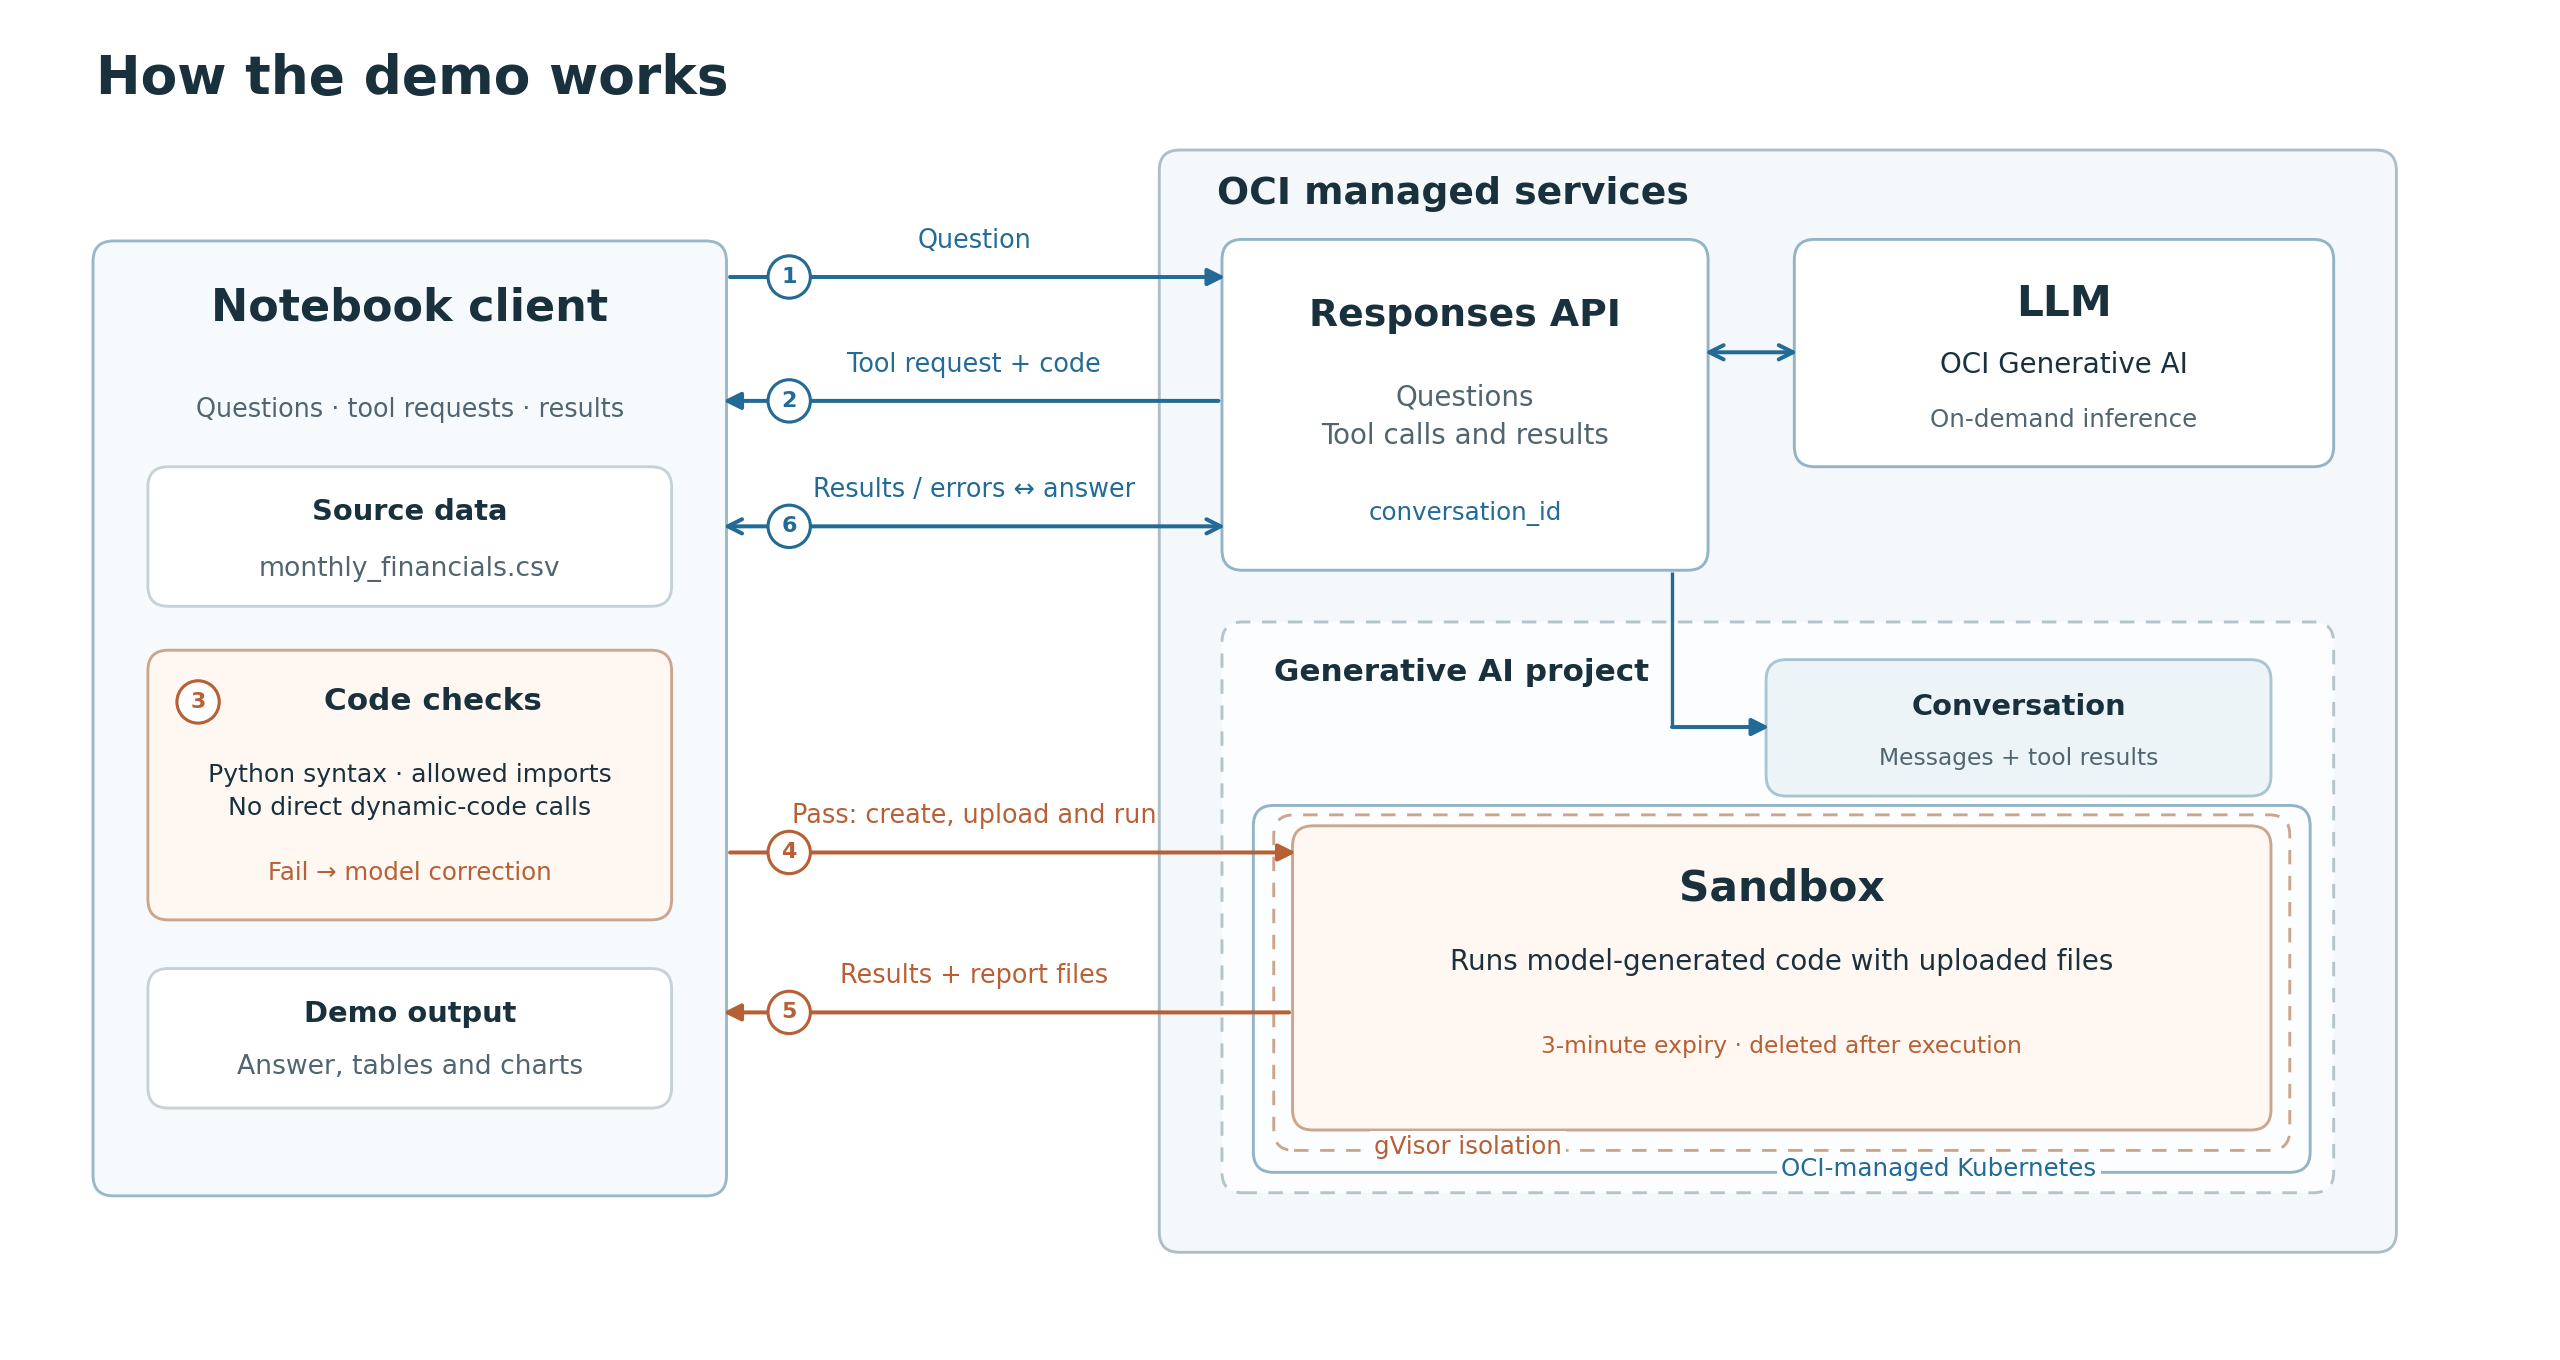


## Sandbox controls

| Capability | User-controlled settings |
|---|---|
| **Outbound networking (egress)** | Project policy: `DENY_ALL`, `ALLOW` for selected domains, or `ALLOW_ALL`. The demo setup script selects `DENY_ALL`. |
| **Inbound application access (ingress)** | Select ports with `publish_ports`, for example `["8080"]`, to expose services through public HTTPS URLs. Applications must enforce their own authentication and authorization. |
| **API authorization** | OCI IAM policies control who can access and use Sandbox APIs. |
| **OCI resource access** | IAM policies determine which OCI resources code can access through the Sandbox's resource principal. |
| **Execution environment** | Currently the `python-3.11` image is available. |
| **Compute capacity** | Choose a shape: `SMALL` (1 OCPU / 4 GB), `MEDIUM` (2 OCPUs / 8 GB), or `LARGE` (4 OCPUs / 16 GB). |


## 1. Connect to OCI

`Inferencing` handles the OCI Responses and Conversations APIs. `Sandboxes` handles isolated Python execution. Both clients use the same OCI session. The classes reuse the OpenAI and OCI SDKs; pandas and Matplotlib display the returned data and charts.

Use a separate project for each participant. Before starting, cleanup removes all `sandboxes-demo-*` Sandboxes in the selected project.


In [ ]:
from demo_utils import available_files, read_json, run_requested_code
from inferencing import Inferencing
from sandboxes import Sandboxes, SandboxTask

import pandas as pd
from IPython.display import display

SANDBOX_RUNTIME = "python-3.11"
SANDBOX_SHAPE = "SMALL"  # 1 OCPU, 4 GB memory
SANDBOX_TTL_MINUTES = 3
SANDBOX_EXECUTION_TIMEOUT_SECONDS = 20

settings = read_json("config.local.json")
inference = Inferencing(settings)
sandboxes = Sandboxes(
    settings, auth=inference.auth, run=inference.run,
    runtime=SANDBOX_RUNTIME,
    shape=SANDBOX_SHAPE,
    expires_in_minutes=SANDBOX_TTL_MINUTES,
    execution_timeout_seconds=SANDBOX_EXECUTION_TIMEOUT_SECONDS,
)
sandboxes.cleanup()


## 2. Introduce the data

The CSV contains synthetic monthly budget and actual figures by product. Amounts are in USD. COGS excludes freight; margin after freight is revenue minus COGS and freight.


In [ ]:
financials = pd.read_csv("assets/monthly_financials.csv")
display(financials)


## 3. Start a conversation

These instructions define how the model uses data, requests code execution and reports results. The tool definition describes the execution request it can send. OCI manages the conversation history; running this cell starts a fresh conversation.


In [ ]:
INSTRUCTIONS = """You are an analyst helping a user explore the available files. Choose how to answer the user's question. Answer directly when the question does not require accessing files or performing an analysis. Base claims about file contents on observed tool results; do not invent figures or claim to have opened files you have not inspected. Ask for clarification when necessary. Keep units and sign conventions explicit. For data analysis, report numerical results only when they appear explicitly in successful tool output: stdout or returned file content. Do not calculate missing totals, percentages or other derived values in your final answer. If a required result is missing, request another execution to compute it and return the result before answering. Treat truncated output as partial evidence; never fill in unseen values. Use the exact measured quantity when describing comparisons. A ranking by level does not establish a ranking by change, sensitivity or cause. Support each interpretation with the relevant computed comparison, or leave it out.

Dataset context: monthly_financials.csv contains month, product, budget_revenue, actual_revenue, budget_cogs, actual_cogs, budget_freight and actual_freight. Each row describes one product in one month. Amounts are USD. COGS excludes freight. “Margin after freight” means revenue less COGS and freight. This describes the columns; choose the calculations and presentation appropriate to the user's question.

The execute_python tool can read the available files, perform calculations and create reports in an isolated Python 3.11 workspace. The application creates a Sandbox only after receiving a tool request. Each execution uses a fresh Sandbox with a three-minute expiration. Saved output files can be supplied to later executions. The tool returns stdout and previews of CSV, JSON and text outputs. Source file contents are available only through execution. Charts are rendered from computed CSV values using a chart specification, so marks and axes use the same scale.

Execution contract:
- Prefer one complete execution per question: inspect the inputs, calculate the requested results, and generate all requested tables and chart specifications in the same program. Use additional executions only when necessary to resolve an error or missing information.
- Supply a complete program using Python's standard library. Do not import or use pandas; it is not installed in the Sandbox. Use Python's csv module to read and write CSV files. Network access, package installation and supplied helper modules are unavailable. Use relative paths; the application chooses the working directory.
- input_files is a JSON array of names from the available file list, or [] when no files are needed. Input files are read-only. Check missing or invalid values relevant to your analysis and state any assumptions.
- output_files lists the new files your program will create, or [] when printed output is sufficient. Choose filenames and report columns appropriate to the question. Supported formats are CSV, JSON, plain text and .chart.json chart specifications. Use unique simple filenames; existing files cannot be overwritten. Keep each file below one megabyte.
- Include every numerical result needed for the answer in stdout or a CSV, JSON or text output, including any requested totals and percentages. Return a compact summary when the full report is too large for a preview. Use finite numbers in JSON, and a header with consistent row lengths in CSV.
- For charts, write a .chart.json file with these keys: kind (bar, line or scatter), data_file (a CSV filename), x (column name), y (list of numeric column names), title, x_label and y_label. Reference a CSV declared in output_files or a previously saved CSV. Use numeric x values for line/scatter charts, and one row per x value for bar/line charts. Label units explicitly; percentage columns should contain percentage values (e.g. 25 for 25%). Do not generate SVG or axis coordinates. The renderer plots the selected CSV values without recalculating them.
- Make one tool request at a time. If it fails, use the returned error to decide whether and how to correct it. Do not present a failed or unexecuted calculation as a result."""


def analysis_instructions():
    files = ", ".join(available_files(inference.run))
    return f"{INSTRUCTIONS}\nAvailable files: {files}"


SANDBOX_EXECUTION_TOOLS = [{
    "type": "function",
    "name": "execute_python",
    "strict": True,
    "description": "Read available files, perform calculations and create reports in a Python workspace.",
    "parameters": SandboxTask.model_json_schema(),
}]

conversation = inference.create_conversation(
    instructions=analysis_instructions,
    tools=SANDBOX_EXECUTION_TOOLS,
)


## 4. Send a question

The model chooses whether it needs to execute code. The sent message and received response appear below; expand or scroll the message view to inspect its content.


In [ ]:
first_question = (
    "Compare budgeted and actual margin after freight for each product in monthly_financials.csv. "
    "Show the comparison in a table and chart, and identify the products with the largest shortfalls."
)
first_response = conversation.send(first_question)


## 5. Run the requested analysis

Check Python syntax, allow only the imports listed below, and reject direct dynamic-code calls. The import list excludes shell and networking libraries. These basic checks do not prove code is safe; execution still happens in an isolated Sandbox.

The same checks run before every execution, including corrections. Rejected code is returned to the model for correction without creating a Sandbox. Successful execution results are returned to the model, and each Sandbox is deleted when processing finishes.


In [ ]:
import ast
from demo_utils import ModelOutputError

ALLOWED_IMPORTS = {
    "csv", "json", "math", "statistics", "decimal", "collections", "itertools",
    "functools", "datetime", "re", "io", "pathlib", "operator", "typing",
}


def validate_code(code):
    try:
        tree = ast.parse(code)
        compile(tree, "analysis.py", "exec")
        for node in ast.walk(tree):
            if isinstance(node, (ast.Import, ast.ImportFrom)):
                modules = ([name.name for name in node.names] if isinstance(node, ast.Import)
                           else [node.module or ""])
                if any(name.split(".")[0] not in ALLOWED_IMPORTS for name in modules):
                    raise ValueError(f"Use only these imports: {', '.join(sorted(ALLOWED_IMPORTS))}")
            if isinstance(node, ast.Call) and isinstance(node.func, ast.Name):
                if node.func.id in {"exec", "eval", "compile", "__import__"}:
                    raise ValueError(f"Dynamic code calls are not allowed: {node.func.id}")
    except (SyntaxError, ValueError) as error:
        print(f"Code validation: rejected — {error}")
        raise ModelOutputError(str(error)) from error
    print("Code validation: passed. Ready for Sandbox execution.")


In [ ]:
run_requested_code(
    conversation=conversation, sandboxes=sandboxes, response=first_response, validate_code=validate_code,
)


## 6. Ask a follow-up

The conversation retains the earlier messages. Each requested execution receives the source data or previously saved reports in a fresh Sandbox.


In [ ]:
follow_up_question = (
    "Using the same data, compare margin after freight if actual freight increases by "
    "5%, 10%, 15% and 20%, with revenue and COGS unchanged. Show total and product-level "
    "results in a table and chart, and identify which product reaches the lowest margin percentage."
)
follow_up_response = conversation.send(follow_up_question)


In [ ]:
run_requested_code(
    conversation=conversation, sandboxes=sandboxes, response=follow_up_response, validate_code=validate_code,
)


## 7. Finish

Each execution shuts down and deletes its Sandbox. This final sweep removes any remaining demo Sandboxes. Generated reports stay in memory until the kernel restarts; conversation history remains in OCI.


In [ ]:
sandboxes.cleanup()
